# Heart Disease Prediction with Support Vector Machine (SVM)
**Mini Project: Classification Algorithms Exploration — Group 6**

## 1. Introduction
Heart disease is one of the leading causes of death worldwide, so detecting it early is very important.

We use the **Heart Failure Prediction** dataset from Kaggle (918 patients, 11 features).
**Goal:** predict whether a patient has heart disease (`HeartDisease` = 1) or not (= 0) using a
**Support Vector Machine (SVM)**.

## 2. Algorithm Explanation: Support Vector Machine

### What is SVM?
SVM is a classification algorithm that finds the **best boundary** that separates two classes
(here: sick vs healthy).

### How does it work?

#### 1. The widest margin
SVM draws a boundary between the two classes and makes the **margin** (the gap between the boundary and the
closest points of each class) **as wide as possible**. A wide margin means the model is more confident and
generalises better to new patients.

#### 2. Support vectors
The points closest to the boundary are called **support vectors**.
Only these points decide where the boundary goes; points far from it don't affect the model.

#### 3. The kernel trick
Sometimes a straight line can't separate the classes.
A **kernel** lets SVM draw a **curved** boundary. The most common is the **RBF kernel**.

> **SVM vs SVR:** it is the same idea as SVR from our regression project. SVR fits a line *through* the points
> (with a tube around it); SVM draws a line *between* two classes (with a margin around it).

### When should SVM be used?
* Small to medium datasets (it becomes slow on very large data).
* Many numerical features.
* When the classes can be separated by a line or a curve.

### Advantages and limitations
| Advantages | Limitations |
|---|---|
| Very accurate on small/medium data | Slow on very large datasets |
| Works well with many features | Needs feature scaling |
| Kernels handle curved boundaries | Needs tuning of C and gamma |
| Wide margin helps avoid overfitting | Hard to interpret (no simple coefficients) |

## 3. Exploratory Data Analysis (EDA)

In [1]:
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Download latest version
path = kagglehub.dataset_download("fedesoriano/heart-failure-prediction")

print("Path to dataset files:", path)
df = pd.read_csv(path + "/heart.csv")
df.head()

Using Colab cache for faster access to the 'heart-failure-prediction' dataset.
Path to dataset files: /kaggle/input/heart-failure-prediction


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB


In [3]:
df.describe()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


In [4]:
df.shape

(918, 12)

### Features and target
| Column | Meaning |
|---|---|
| `Age` | Age of the patient (years) |
| `Sex` | M = male, F = female |
| `ChestPainType` | Chest pain type: TA, ATA, NAP, ASY (ASY = no symptoms) |
| `RestingBP` | Resting blood pressure (mm Hg) |
| `Cholesterol` | Serum cholesterol (mg/dl) |
| `FastingBS` | Fasting blood sugar > 120 mg/dl (1 = yes) |
| `RestingECG` | Resting electrocardiogram result: Normal, ST, LVH |
| `MaxHR` | Maximum heart rate reached |
| `ExerciseAngina` | Chest pain during exercise (Y / N) |
| `Oldpeak` | ST depression (ECG change during exercise) |
| `ST_Slope` | Slope of the ST segment: Up, Flat, Down |
| **`HeartDisease`** | **Target:** 1 = heart disease, 0 = normal |

## Data cleaning

In [5]:
print(df.isna().sum().sum(), "missing values")
print(df.duplicated().sum(), "duplicated rows")
print((df['Cholesterol'] == 0).sum(), "rows with Cholesterol = 0")
print((df['RestingBP'] == 0).sum(), "rows with RestingBP = 0")

0 missing values
0 duplicated rows
172 rows with Cholesterol = 0
1 rows with RestingBP = 0


There are no empty cells, but **some values are 0**, which is impossible for a living person
(cholesterol or blood pressure can't be 0). These are **hidden missing values**:
* `RestingBP = 0`: only one row, so we **remove it**.
* `Cholesterol = 0`: too many rows to remove, so we **replace 0 with the median** of the real values.

In [6]:
df = df[df['RestingBP'] > 0]
chol_median = df.loc[df['Cholesterol'] > 0, 'Cholesterol'].median()
df['Cholesterol'] = df['Cholesterol'].replace(0, chol_median)

print("Cholesterol median used:", chol_median)
df.shape

Cholesterol median used: 237.0


(917, 12)

## Target and outliers

HeartDisease
1    507
0    410
Name: count, dtype: int64
HeartDisease
1    0.55
0    0.45
Name: proportion, dtype: float64


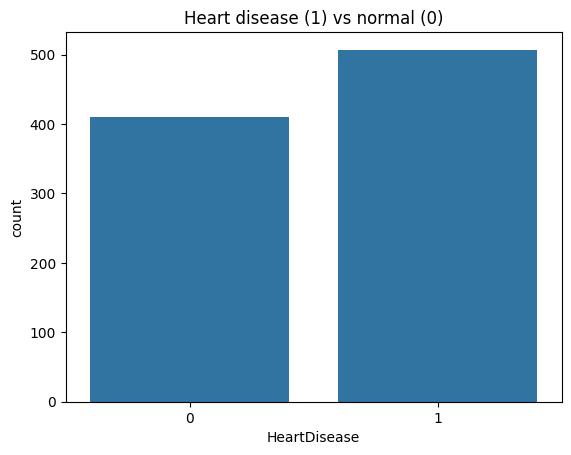

In [7]:
print(df['HeartDisease'].value_counts())
print(df['HeartDisease'].value_counts(normalize=True).round(2))
sns.countplot(x='HeartDisease', data=df)
plt.title("Heart disease (1) vs normal (0)")
plt.show()

About **55%** of patients have heart disease (507) and **45%** are normal (410).
The two classes are **fairly balanced**, so accuracy is a meaningful metric (we will still check precision,
recall and F1).

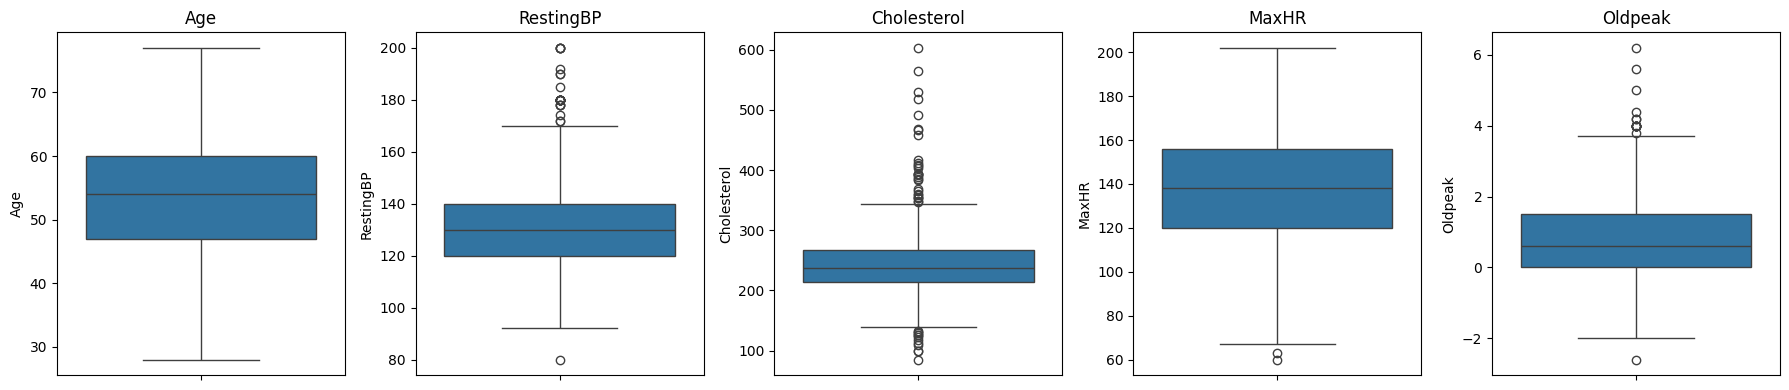

Age outliers: 0
RestingBP outliers: 27
Cholesterol outliers: 41
MaxHR outliers: 2
Oldpeak outliers: 16


In [8]:
num_cols = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']

fig, ax = plt.subplots(1, 5, figsize=(18, 4))
for i, col in enumerate(num_cols):
    sns.boxplot(y=df[col], ax=ax[i])
    ax[i].set_title(col)
plt.tight_layout()
plt.show()

for col in num_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
    print(col, "outliers:", n)

The IQR method flags outliers in `Cholesterol` (41), `RestingBP` (27), `Oldpeak` (16) and `MaxHR` (2); `Age` has none.
**We keep them**, because they are medically possible values (very high blood pressure or cholesterol happens in
real patients), not data errors. Scaling will also reduce their effect on SVM.

# H1

Men have heart disease more often than women.

Sex
F    0.26
M    0.63
Name: HeartDisease, dtype: float64


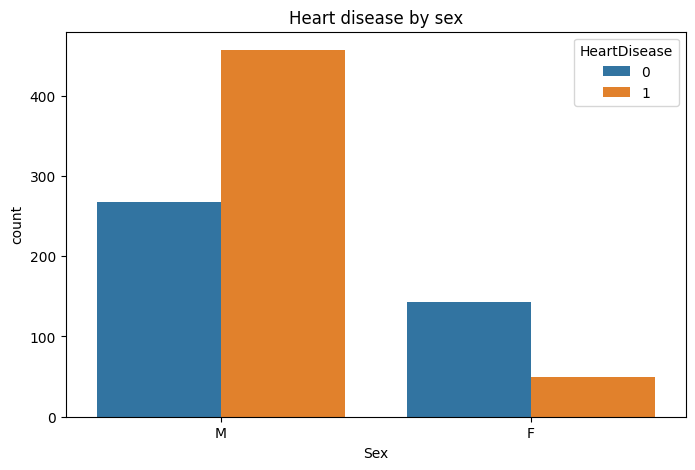

In [9]:
print(df.groupby('Sex')['HeartDisease'].mean().round(2))
plt.figure(figsize=(8, 5))
sns.countplot(x='Sex', hue='HeartDisease', data=df)
plt.title("Heart disease by sex")
plt.show()

# A1
**Confirmed.** 63% of men have heart disease versus 26% of women, so men are about **2.4×** more likely to have it.

# H2

Older patients have heart disease more often.

HeartDisease
0    50.6
1    55.9
Name: Age, dtype: float64


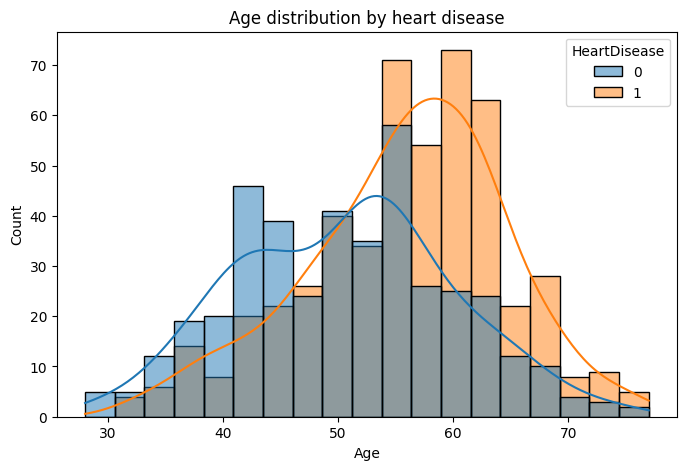

In [10]:
print(df.groupby('HeartDisease')['Age'].mean().round(1))
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='Age', hue='HeartDisease', kde=True)
plt.title("Age distribution by heart disease")
plt.show()

# A2
**Confirmed.** Patients with heart disease are older on average: **55.9** years versus **50.6** for normal patients
(about 5 years older). The histogram shows heart disease becomes more common after about 55.

# H3

Patients who get chest pain during exercise (`ExerciseAngina` = Y) have heart disease more often.

ExerciseAngina
N    0.35
Y    0.85
Name: HeartDisease, dtype: float64

ChestPainType
ASY    0.79
ATA    0.14
NAP    0.35
TA     0.43
Name: HeartDisease, dtype: float64


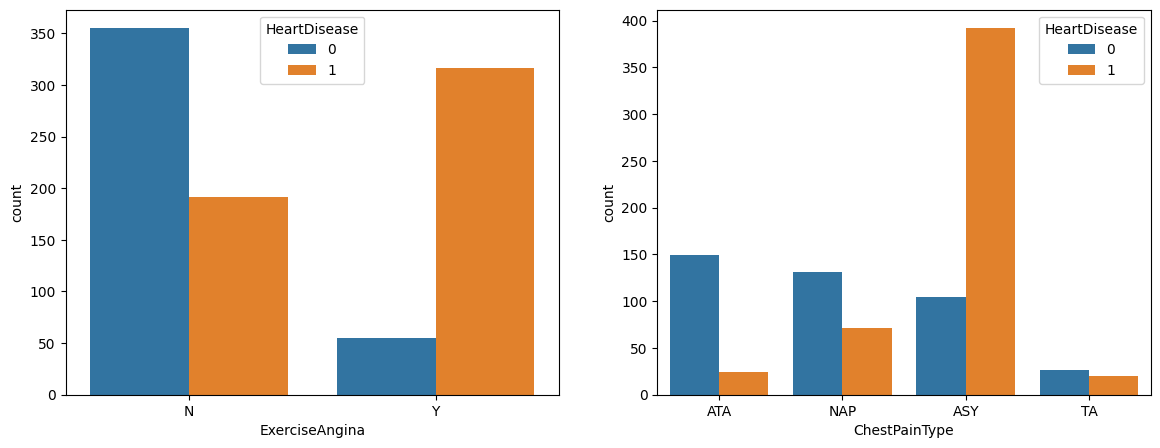

In [11]:
print(df.groupby('ExerciseAngina')['HeartDisease'].mean().round(2))
print()
print(df.groupby('ChestPainType')['HeartDisease'].mean().round(2))
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.countplot(x='ExerciseAngina', hue='HeartDisease', data=df, ax=ax[0])
sns.countplot(x='ChestPainType', hue='HeartDisease', data=df, ax=ax[1])
plt.show()

# A3
**Confirmed, and it is a strong effect.** 85% of patients with exercise angina have heart disease versus 35% without it.

For chest pain type, the highest rate is in **ASY (asymptomatic, 79%)**: surprisingly, patients with *no* typical chest
pain symptoms are the most likely to have heart disease, while ATA patients have the lowest rate (14%).
This shows that "no symptoms" does not mean "no risk".

# H4

Higher cholesterol means more heart disease.

HeartDisease
0    238.7
1    246.9
Name: Cholesterol, dtype: float64


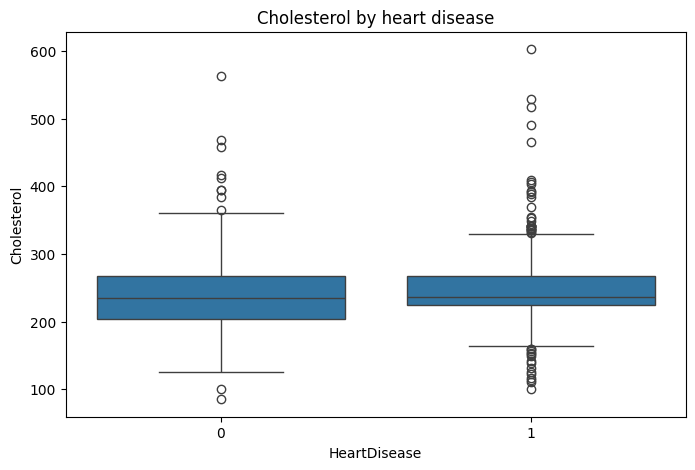

In [12]:
print(df.groupby('HeartDisease')['Cholesterol'].mean().round(1))
plt.figure(figsize=(8, 5))
sns.boxplot(x='HeartDisease', y='Cholesterol', data=df)
plt.title("Cholesterol by heart disease")
plt.show()

# A4
**Not confirmed.** Patients with heart disease have an average cholesterol of **246.9** versus **238.7** for normal
patients: a very small difference, and its correlation with heart disease is only **0.08**.
Note that 172 cholesterol values were missing (0) and were filled with the median, which can hide part of a real effect.

## Correlation

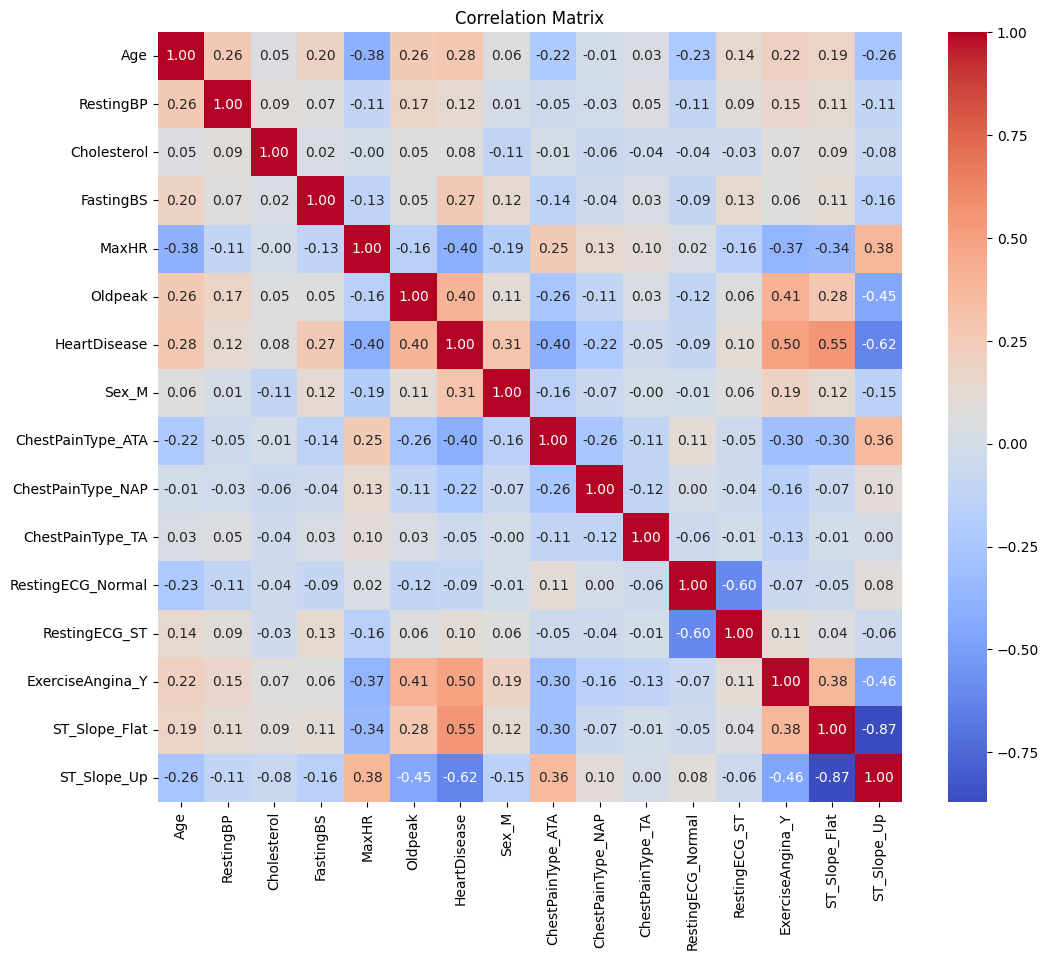

,HeartDisease
ST_Slope_Up,-0.62
ST_Slope_Flat,0.55
ExerciseAngina_Y,0.50
Oldpeak,0.40
ChestPainType_ATA,-0.40
MaxHR,-0.40
Sex_M,0.31
Age,0.28
FastingBS,0.27
ChestPainType_NAP,-0.22


In [13]:
df_corr = pd.get_dummies(df, drop_first=True, dtype=int)

plt.figure(figsize=(12, 10))
sns.heatmap(df_corr.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()

df_corr.corr()['HeartDisease'].drop('HeartDisease').sort_values(key=abs, ascending=False).round(2)

The features most related to `HeartDisease` are **`ST_Slope`** (Up −0.62, Flat +0.55), **`ExerciseAngina`** (+0.50)
and **`Oldpeak`** (+0.40), followed by `MaxHR` (−0.40), `ChestPainType_ATA` (−0.40) and `Sex_M` (+0.31).
`Cholesterol` (0.08) and `RestingBP` (0.12) are among the weakest.
(Negative values mean the feature goes with *less* heart disease, e.g. a higher `MaxHR` or an upward `ST_Slope`.)

# EDA Summary
| | Result |
|---|---|
| Data quality | No empty cells or duplicates; hidden zeros fixed (1 row removed, 172 Cholesterol zeros replaced with the median 237) |
| Target | Fairly balanced: 55% heart disease, 45% normal |
| Outliers | Kept: medically possible values |
| H1 Sex | Confirmed: men 63% vs women 26% |
| H2 Age | Confirmed: 55.9 vs 50.6 years |
| H3 Exercise angina | Confirmed, strong: 85% vs 35%; ASY chest pain 79% |
| H4 Cholesterol | Not confirmed: 246.9 vs 238.7, correlation 0.08 |

**Ranking of factors:** ST_Slope > ExerciseAngina > Oldpeak ≈ MaxHR ≈ ChestPainType > Sex > Age > Cholesterol.

# Model

## Key hyperparameters
| Parameter | What it controls | Too low | Too high |
|---|---|---|---|
| **C** | Penalty for misclassified points | Too simple (underfits) | Chases every point (overfits) |
| **γ (gamma)** | How curvy the boundary can be (RBF) | Too smooth | Too wiggly (overfits) |
| **kernel** | Shape of the boundary: linear, poly, rbf | — | — |

In [14]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, ConfusionMatrixDisplay)

## Data preprocessing
* **Encoding:** `Sex`, `ChestPainType`, `RestingECG`, `ExerciseAngina` and `ST_Slope` are text, so we turn them
  into 0/1 columns with `get_dummies`.
* **Split:** 80% train, 20% test. `stratify=y` keeps the same sick/healthy ratio in both sets.

In [15]:
df_model = pd.get_dummies(df, drop_first=True, dtype=int)

X = df_model.drop(columns=["HeartDisease"])
y = df_model["HeartDisease"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (733, 15)  Test: (184, 15)


In [16]:
results = {}

def evaluate(name, y_true, y_pred):
    results[name] = {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred),
    }
    print(name)
    for metric, value in results[name].items():
        print(f"{metric}: {value:.3f}")
    print()

### Model 1: SVM without scaling
We first train SVM with default settings (RBF kernel, C=1) on the **raw** features, to see why scaling matters.

In [17]:
svm_raw = SVC()
svm_raw.fit(X_train, y_train)
evaluate("SVM (no scaling)", y_test, svm_raw.predict(X_test))

SVM (no scaling)
Accuracy: 0.734
Precision: 0.739
Recall: 0.804
F1: 0.770



**Result:** Accuracy = **0.734**, F1 = 0.770.
SVM is based on distances, so features with large numbers (like `Cholesterol`, around 200) dominate features with
small numbers (like `Oldpeak`, around 1).

### Feature scaling
`StandardScaler` puts all features on the same scale (mean 0, standard deviation 1).
The scaler is fitted on the training data only, to avoid leaking information from the test set.

In [18]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

### Model 2: SVM with scaled features

In [19]:
svm = SVC()
svm.fit(X_train, y_train)
evaluate("SVM (scaled)", y_test, svm.predict(X_test))

SVM (scaled)
Accuracy: 0.859
Precision: 0.858
Recall: 0.892
F1: 0.875



**Result:** Accuracy = **0.859**, F1 = **0.875**.
Scaling **improved** the model a lot: accuracy jumped from 0.734 to 0.859 (+12.5 points).

### Model 3: Tuned SVM
We use GridSearchCV (5-fold cross-validation) to find the best kernel, C and gamma.

In [20]:
params = {
    "kernel": ["linear", "rbf"],
    "C": [0.1, 1, 10, 100],
    "gamma": ["scale", 0.01, 0.1, 1]
}
grid = GridSearchCV(SVC(), params, cv=5, scoring="f1")
grid.fit(X_train, y_train)
print("Best params:", grid.best_params_)
evaluate("SVM (tuned)", y_test, grid.predict(X_test))

Best params: {'C': 1, 'gamma': 'scale', 'kernel': 'rbf'}
SVM (tuned)
Accuracy: 0.859
Precision: 0.858
Recall: 0.892
F1: 0.875



**Result:** Accuracy = **0.859**, F1 = **0.875**, the same as Model 2.
Best settings: kernel = **rbf**, C = **1**, gamma = **scale**. These are exactly the default settings, so tuning
confirmed that the defaults were already the best choice in our search grid.

### Model 4: Recall-focused SVM
In medicine, **missing a sick patient (false negative) is the most dangerous mistake**, because that patient
would not get treatment. So we tune SVM to find **more sick patients (higher recall)**:

* **`class_weight`:** tells SVM that a mistake on a sick patient costs more. `{0: 1, 1: 2}` means missing a sick
  patient costs double; `"balanced"` sets the weights automatically.
* **F2 score:** instead of F1, GridSearchCV picks the model with the best **F2**, which gives recall more weight
  than precision. (We don't use plain `recall`, because a model that calls everyone sick gets recall = 100%.)
* **Wider search:** more values of C and gamma, and the `poly` kernel.

Best params: {'C': 0.1, 'class_weight': {0: 1, 1: 2}, 'gamma': 0.1, 'kernel': 'poly'}
SVM (recall-focused)
Accuracy: 0.826
Precision: 0.787
Recall: 0.941
F1: 0.857



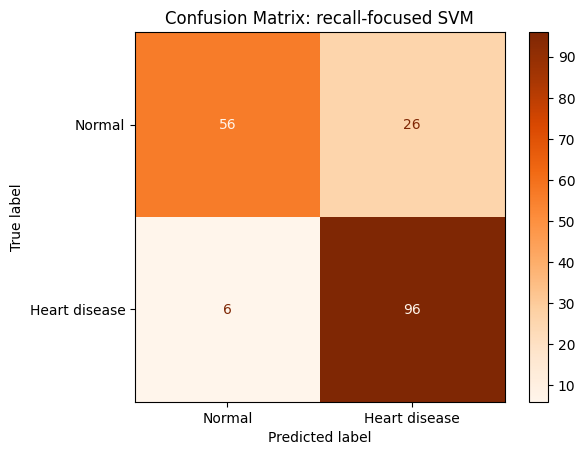

In [21]:
from sklearn.metrics import make_scorer, fbeta_score

f2 = make_scorer(fbeta_score, beta=2)
params = {
    "kernel": ["rbf", "linear", "poly"],
    "C": [0.1, 0.5, 1, 5, 10, 50],
    "gamma": ["scale", 0.001, 0.01, 0.05, 0.1],
    "class_weight": [None, "balanced", {0: 1, 1: 2}],
}
grid2 = GridSearchCV(SVC(), params, cv=5, scoring=f2, n_jobs=-1)
grid2.fit(X_train, y_train)
print("Best params:", grid2.best_params_)
evaluate("SVM (recall-focused)", y_test, grid2.predict(X_test))

ConfusionMatrixDisplay.from_predictions(y_test, grid2.predict(X_test),
                                        display_labels=["Normal", "Heart disease"], cmap="Oranges")
plt.title("Confusion Matrix: recall-focused SVM")
plt.show()

**Result:** Recall = **0.941** (vs 0.892 for Model 3), Precision = **0.787**, Accuracy = **0.826**, F1 = 0.857.
Best settings: kernel = **poly**, C = **0.1**, gamma = **0.1**, class_weight = **{0: 1, 1: 2}**.
Out of 102 sick patients, the model now finds **96** and misses only **6** (vs 11 for Model 3).

**Trade-off:** false alarms went up from 15 to **26** healthy patients flagged as sick, so precision and accuracy
went down. In medicine this is acceptable: an extra check-up for a healthy person is much less harmful than
missing a sick one.

### Confusion matrix (tuned SVM)
* **True positives:** sick patients correctly found.
* **False negatives:** sick patients the model called healthy. **This is the most dangerous mistake**, because
  a sick patient would not get treatment. That is why **recall** matters most here.

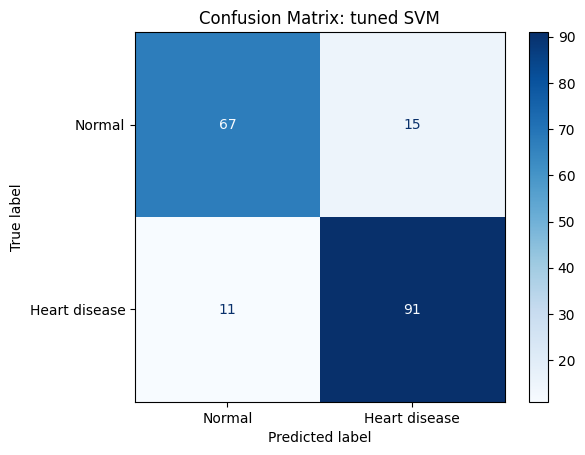

               precision    recall  f1-score   support

       Normal       0.86      0.82      0.84        82
Heart disease       0.86      0.89      0.88       102

     accuracy                           0.86       184
    macro avg       0.86      0.85      0.86       184
 weighted avg       0.86      0.86      0.86       184



In [22]:
y_pred = grid.predict(X_test)
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["Normal", "Heart disease"], cmap="Blues")
plt.title("Confusion Matrix: tuned SVM")
plt.show()

print(classification_report(y_test, y_pred, target_names=["Normal", "Heart disease"]))

Out of **102** sick patients in the test set, the model correctly found **91** and missed **11** (false negatives).
Out of 82 normal patients, it correctly identified 67 and wrongly flagged **15** as sick (false positives).

### Bonus: comparison with Logistic Regression
We compare SVM against Logistic Regression, a simpler linear model.

In [23]:
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train, y_train)
evaluate("Logistic Regression", y_test, lr.predict(X_test))

Logistic Regression
Accuracy: 0.875
Precision: 0.883
Recall: 0.892
F1: 0.888



In [24]:
pd.DataFrame(results).T.round(3)

,Accuracy,Precision,Recall,F1
SVM (no scaling),0.734,0.739,0.804,0.770
SVM (scaled),0.859,0.858,0.892,0.875
SVM (tuned),0.859,0.858,0.892,0.875
SVM (recall-focused),0.826,0.787,0.941,0.857
Logistic Regression,0.875,0.883,0.892,0.888


**Result:** Logistic Regression reached F1 = **0.888** and accuracy = **0.875**, slightly higher than the tuned SVM
(F1 0.875, accuracy 0.859). Both models have the **same recall (0.892)**: they find the same share of sick patients.

This is a valid finding: it means the boundary between sick and healthy patients is **close to a straight line**,
so a simpler linear model works as well as SVM here. A simpler model is preferred when it performs equally well.
We did **not** keep re-tuning on the test set until SVM won, because that would make the evaluation unfair.
However, the **recall-focused SVM (Model 4)** reached **recall 0.941**, the highest of all models: it misses only
6 sick patients, compared with 11 for Logistic Regression and the tuned SVM. So if finding sick patients is the
priority, the recall-focused SVM is the best choice.

# Conclusion
* The strongest signs of heart disease in this data are **`ST_Slope`** (a flat slope), **exercise angina** and
  **`Oldpeak`**. Men, older patients and patients with *asymptomatic* (ASY) chest pain are also at higher risk.
  Surprisingly, cholesterol had almost no effect.
* Cleaning the hidden zeros and **scaling** were essential: scaling alone raised SVM accuracy from 0.734 to 0.859.
* The tuned SVM reached **accuracy 0.859** and **recall 0.892**: it finds about **89%** of sick patients
  (91 of 102 in the test set).
* Logistic Regression scored slightly higher (accuracy 0.875), with the same recall. The data is close to linearly
  separable, so SVM's curved RBF boundary gave no extra advantage.
* The **recall-focused SVM** (class weights + F2 score) raised recall to **0.941**: it finds **94%** of sick
  patients and misses only 6, the best of all models, at the cost of more false alarms (26 vs 15).
* **Limitation:** even the best model still misses some sick patients (6 false negatives), so in real life it should support
  a doctor's decision, not replace it.